<a href="https://colab.research.google.com/github/GalynaGnatenko/GnatenkoGalyna/blob/main/%D0%93%D0%BD%D0%B0%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_%22HW_11_1_%D0%92%D1%96%D0%B7%D1%83%D0%B0%D0%BB%D1%96%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%B4%D0%B0%D0%BD%D0%B8%D1%85_%D0%B7_Pandas_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Візуалізація даних з Pandas

## Опис завдання
У цьому домашньому завданні ви працюватимете з датасетом про оренду велосипедів `yulu_rental.csv`. Датасет містить інформацію про кількість орендованих велосипедів залежно від погодних умов, сезону та інших факторів.
Набір даних взяти з Kaggle. Посилання на оригінальний [опис](https://www.kaggle.com/datasets/ranitsarkar01/yulu-bike-sharing-data?select=yulu_bike_sharing_dataset.csv).

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів



---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.


Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Підготовка даних


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Завантаження даних
df = pd.read_csv('/content/drive/MyDrive/Data/yulu_rental.csv')

In [6]:
df

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
10881,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336
10882,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241
10883,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168
10884,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129


In [7]:
# Перетворення datetime у правильний формат
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour

## Завдання 0: Перегляд даних
**Завдання:**
Перегляньте дані, їх розмір, та напишіть висновок:
- скільки даних в наборі
- який рівень деталізації мають ці дані, тобто за який період міститься дані в одному рядку даних ?

In [8]:
df

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
datetime,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3
2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336,2012-12-19,19,51,2,Wednesday,2012,12,19
2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241,2012-12-19,19,51,2,Wednesday,2012,12,20
2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168,2012-12-19,19,51,2,Wednesday,2012,12,21


In [9]:
df['year'].unique().tolist()

[2011, 2012]

In [10]:
[df['date'].min(), df['date'].max()]

[datetime.date(2011, 1, 1), datetime.date(2012, 12, 19)]

В наборі 10886 rows × 19 columns  - стільки даних. Якщо вивести унікальні роки, то в наборі присутні дані за 2011 та 2012 рік. З 1 січня 2011 року майже по кінець 2012 року  - по 19 грудня

## Завдання 1: Базовий лінійний графік

**Завдання:**
1. Згрупуйте дані про кількість орендованих велосипедів (`count`) поденно.
2. Побудуйте з методом `DataFrame.plot()` лінійний графік поденної кількості орендованих велосипедів (`count`) за весь період в даних.
3. Налаштуйте розмір графіка (12x6), додайте заголовок "Динаміка оренди велосипедів" та сітку.
4. Дайте відповіді на питання по цьому графіку. Якщо треба - проведіть додаткові програмні операції для відповідей.

**Питання для інтерпретації:**
1. Як гадаєте, чому графік має "заломи", чим це спричинено і як ви б могли прибрати заломи?
2. Які загальні тенденції ви бачите на графіку?
3. Чи помітні якісь сезонні коливання?
4. Чи є періоди з аномально високими або низькими значеннями і чому на ваш погляд можуть бути ці аномалії?


In [11]:
# Поденна кількість

dayly_count = df['count'].resample('D').count()
dayly_count

,count
datetime,
2011-01-01,24
2011-01-02,23
2011-01-03,22
2011-01-04,23
2011-01-05,23
...,...
2012-12-15,24
2012-12-16,24
2012-12-17,24


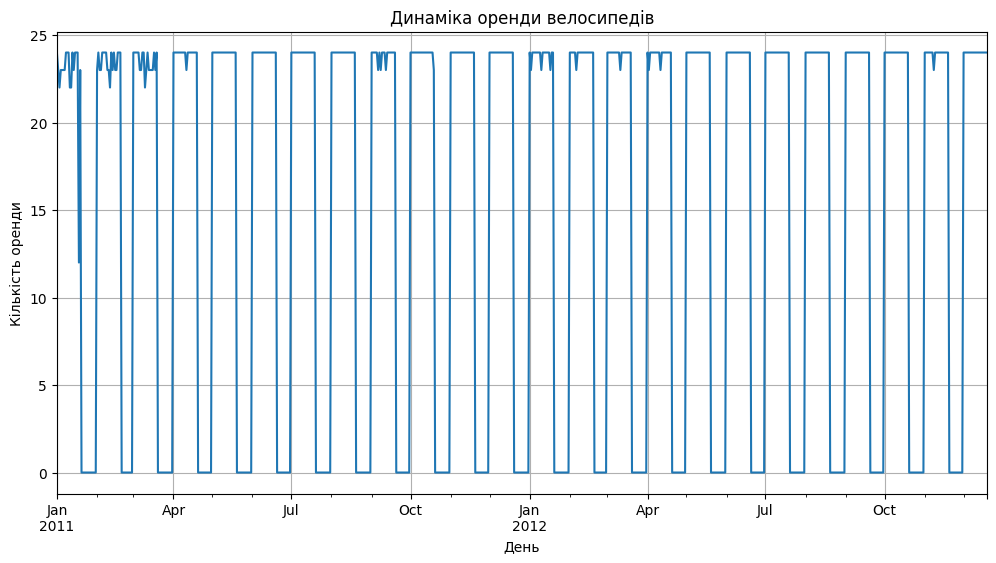

In [12]:
dayly_count.plot(
    kind='line',
    figsize=(12, 6),
    title='Динаміка оренди велосипедів',
    xlabel='День',
    ylabel='Кількість оренди',
    grid=True
);

Cпостерігаються значні стрибки в значеннях між днями. Нульова кількість оренди, а потім максимальна кількість оренди. Такий паттер зберігається обидва роки. Може це стрибок між вихідними та будніми днями....


## Завдання 2: Аналіз сезонності (Bar Plot)

**Завдання:**
Побудуйте вертикальну стовпчасту діаграму середньої кількості орендованих велосипедів за сезонами(кварталами). Додайте підписи осей і заголовок.

Просунуте доповнення:
1. Позначте квартали не числом, а назвою на візуалізації.
2. Додайте підписи над стовпцями зі значеннями в кожному стовпці.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В який квартал найбільша середня кількість оренди велосипедів?
2. Як ви можете пояснити таку сезонну закономірність?
3. У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталми?

In [13]:
season_year_avg = df.groupby(['season', df.index.year])['count'].mean().round()
season_year_avg = season_year_avg.unstack()
season_names = {1: 'Зима', 2: 'Весна', 3: 'Літо', 4: 'Осінь'}
season_year_avg.index = season_year_avg.index.map(season_names)
season_year_avg

datetime,2011,2012
season,,
Зима,72.0,159.0
Весна,161.0,270.0
Літо,187.0,282.0
Осінь,155.0,243.0


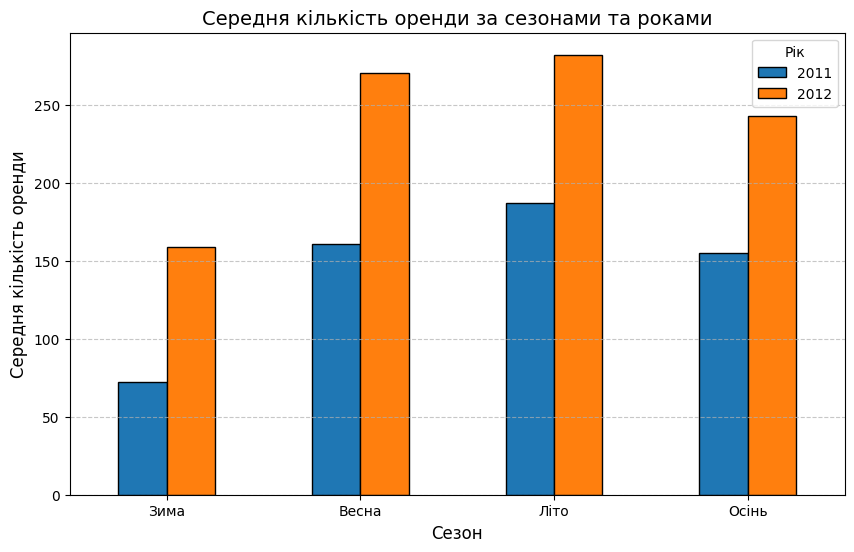

In [14]:
ax = season_year_avg.plot(kind='bar', figsize=(10, 6), edgecolor='black')

plt.title('Середня кількість оренди за сезонами та роками', fontsize=14)
plt.xlabel('Сезон', fontsize=12)
plt.ylabel('Середня кількість оренди', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Рік')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

1. В який квартал найбільша середня кількість оренди велосипедів? - влітку
2. Як ви можете пояснити таку сезонну закономірність? - це логічно. влітку катаються на велосипедах більше ніж взимку
3. У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталми? - кількість орендованих велосипедів між літом та зимою відрізняється майже вдвічі. Влітку катаються майже вдвічі більше ніз взимку

## Завдання 3: Динаміка за місяцями (Line Plot)

**Завдання:**
Створіть лінійний графік середньої кількості оренд велосипедів на годину по місяцях (тобто групування в рамках місяця і беремо середню кількість оренд у цей місяць з кількох років). Використайте маркери-кружечки для точок, додайте сітку та пофарбуйте лінію у червоний колір.

Просунуте доповнення:
- додайте аби по осі ОХ поділки були чітко на кожен окремий місяць по одній. Тобто сумарно 12 поділок.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які місяці спостерігається пік та спад оренди?
2. Чи збігається ця закономірність з результатами з попереднього завдання?
3. Як може вплинути клімат на оренду велосипедів протягом року?


In [15]:
monthly_avg = df.groupby('month')['count'].mean().round()
monthly_avg

,count
month,
1,90.0
2,110.0
3,148.0
4,184.0
5,219.0
6,242.0
7,235.0
8,234.0
9,234.0


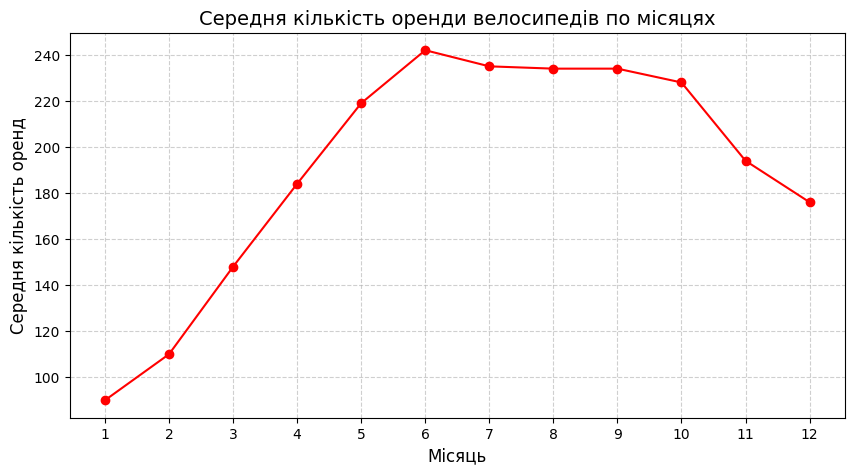

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_avg.index,        # Вісь X: номери місяців (1, 2, ..., 12)
    monthly_avg.values,       # Вісь Y: середні значення
    color='red',              # Червона лінія
    marker='o',               # Маркери-кружечки
    linestyle='-'
)

plt.title('Середня кількість оренди велосипедів по місяцях', fontsize=14)
plt.xlabel('Місяць', fontsize=12)
plt.ylabel('Середня кількість оренд', fontsize=12)

plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Питання для інтерпретації:

1. В які місяці спостерігається пік та спад оренди? - пік в 6 місяці, спад в - 1
2. Чи збігається ця закономірність з результатами з попереднього завдання? - так збігається. бо шостий місяць - це червень або літо. а перший місяць це зима
3. Як може вплинути клімат на оренду велосипедів протягом року? - клімат впливає напряму - какататися в теплі погожі дні приємніше ніж коли слизько та йде сніг

## Завдання 4: Розподіл погодних умов (Pie Chart)

**Завдання:**
1. Побудуйте кругову діаграму з часткою записів за погодними умовами
2. Додайте підписи з відсотками та легенду з описами погоди (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ).
3. Визначте свої відмінні від стандартних кольори для відображення кожної категорії.
4. Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. Яка погода переважає в датасеті?
2. Чи є дні із сильним дощем? Яка їх частка?
3. Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів?

Очікуваний результат:

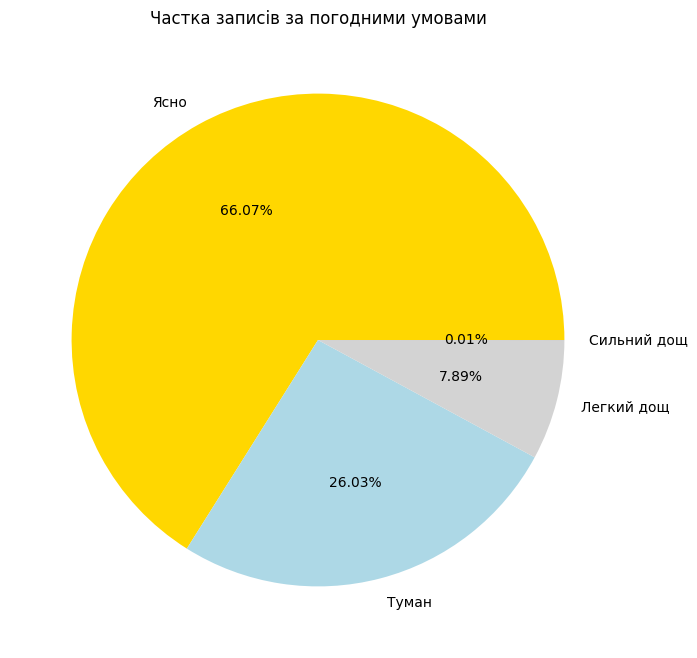

In [17]:
weather_labels = {
    1: '1: Ясно',
    2: '2: Туман',
    3: '3: Легкий дощ',
    4: '4: Сильний дощ'
}
weather_counts = df['weather'].map(weather_labels).value_counts()
print(weather_counts)

weather
1: Ясно           7192
2: Туман          2834
3: Легкий дощ      859
4: Сильний дощ       1
Name: count, dtype: int64


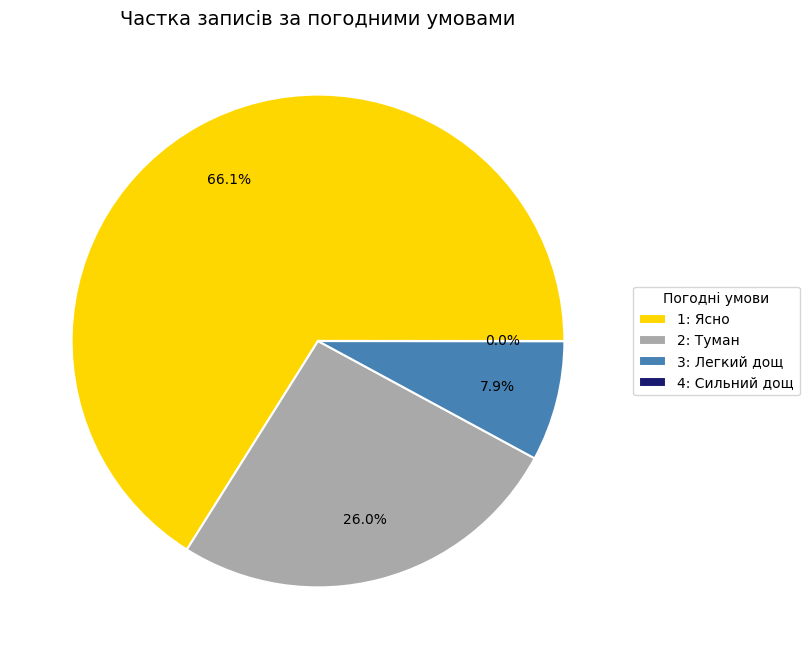

In [18]:
plt.figure(figsize=(8, 8))
plt.pie(
    weather_counts,
    labels=None,
    autopct='%1.1f%%',
    pctdistance=0.75,
    colors=['#ffd700', '#a9a9a9', '#4682b4', '#191970'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

plt.title('Частка записів за погодними умовами', fontsize=14)
plt.legend(weather_counts.index, title="Погодні умови", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
plt.show()

## Завдання 5: Box Plot для аналізу викидів

**Завдання:**
Створіть коробковий графік (box plot) кількості орендованих велосипедів для кожного типу погоди.

Просунуте доповнення:
- Використайте горизонтальну орієнтацію.
- Позначте погодні умови не числом, а назвою на візуалізації.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. При якій погоді найбільший розкид у кількості оренди?
2. Чи є викиди (outliers) в даних? При якій погоді?
3. При якій погоді медіанне значення оренди найвище?

In [19]:
import matplotlib.pyplot as plt

In [23]:
weather_labels = {
    1: '1: Ясно',
    2: '2: Туман',
    3: '3: Легкий дощ',
    4: '4: Сильний дощ'
}


df['weather_name'] = df['weather'].map(weather_labels)

<Figure size 1000x600 with 0 Axes>

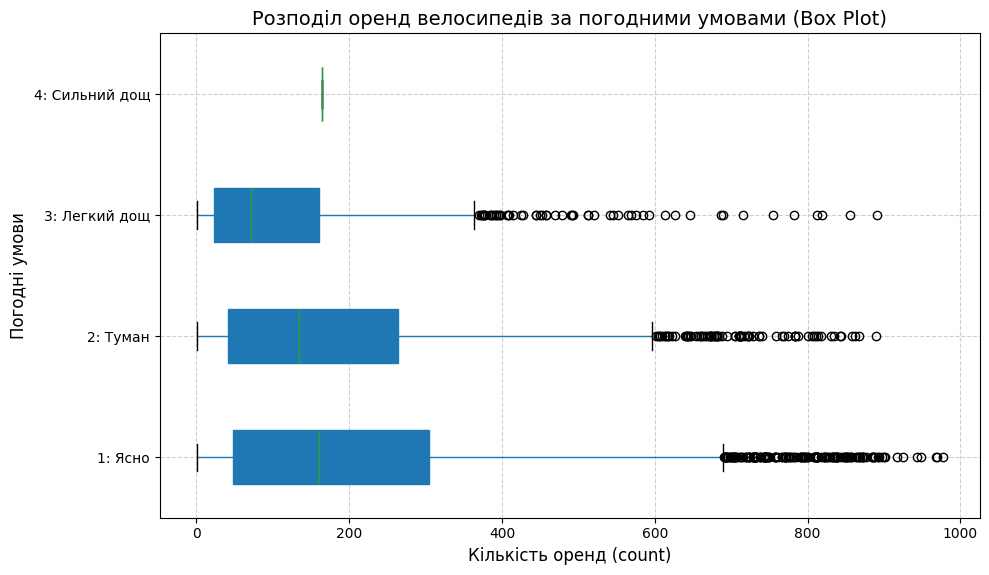

In [24]:
plt.figure(figsize=(10, 6))
df.boxplot(
    column='count',
    by='weather_name',
    vert=False,
    patch_artist=True,
    figsize=(10, 6)
)


plt.title('Розподіл оренд велосипедів за погодними умовами (Box Plot)', fontsize=14)
plt.suptitle('')
plt.xlabel('Кількість оренд (count)', fontsize=12)
plt.ylabel('Погодні умови', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Питання для інтерпретації:

1. При якій погоді найбільший розкид у кількості оренди? - при легкому дощі. є середня кількість оренди. але викидів дуже багато.
2. Чи є викиди (outliers) в даних? При якій погоді? викидів немає тільки при сильному дощі. при всих інших погодах є середня кількість та є викиди
3. При якій погоді медіанне значення оренди найвище? - при ясній погоди медіанне значення майже близько до 200.

## Завдання 6: Кореляція температури та оренди (Scatter Plot)

**Завдання:**
Побудуйте діаграму розсіювання залежності між температурою (`temp`) та загальною кількістю оренди (`count`). Розфарбуйте точки за сезонами, додайте напівпрозорість (alpha=0.6).

**Увага!** За замовченням буде колір

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
- Чи є зв'язок між температурою та кількістю оренди? Який?

Text(0, 0.5, 'Загальна кількість оренд (count)')

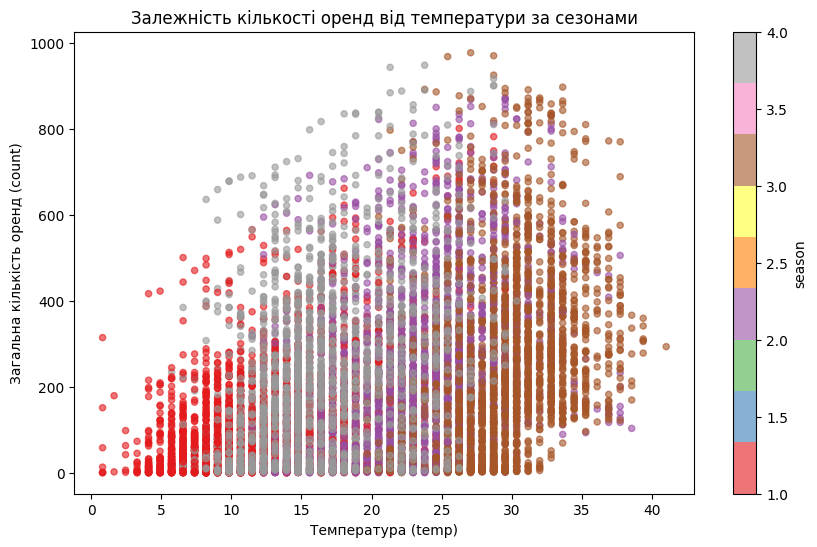

In [27]:
ax = df.plot.scatter(
    x='temp',
    y='count',
    c='season',
    colormap='Set1',
    alpha=0.6,
    figsize=(10, 6),
    title='Залежність кількості оренд від температури за сезонами'
)

# 2. Підписи осей
ax.set_xlabel('Температура (temp)')
ax.set_ylabel('Загальна кількість оренд (count)')

Чи є зв'язок між температурою та кількістю оренди? Який? - якось дуже рясно. але точно видно до від 10 до 30 градусів дані дуже скупчилися. до 10 градусів та поза 35 дані розсіяні. тобто в більш приємну температура для тіла люди катаються більше

## (Опціонально) Завдання 7: Порівняння користувачів (Stacked Bar Chart)

**Завдання:**
Ми хочемо дізнатись як по дням тижня беруть в середньому в оренду велосипеди випадкові і зареєстровані користувачі.

Створіть стовпчасту діаграму з накопиченням (bar з налаштуванням `stacked=True`), яка показує співвідношення випадкових (`casual`) та зареєстрованих (`registered`) користувачів по днях тижня за кількістю взятих ними велосипедів в оренду в середньому. Використайте різні кольори для типів користувачів.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які дні тижня більше оренд від зареєстрованих користувачів?
2. Як ви можете пояснити таку різницю в поведінці користувачів протягом тижня?

Text(0, 0.5, 'Середня кількість оренд на годину')

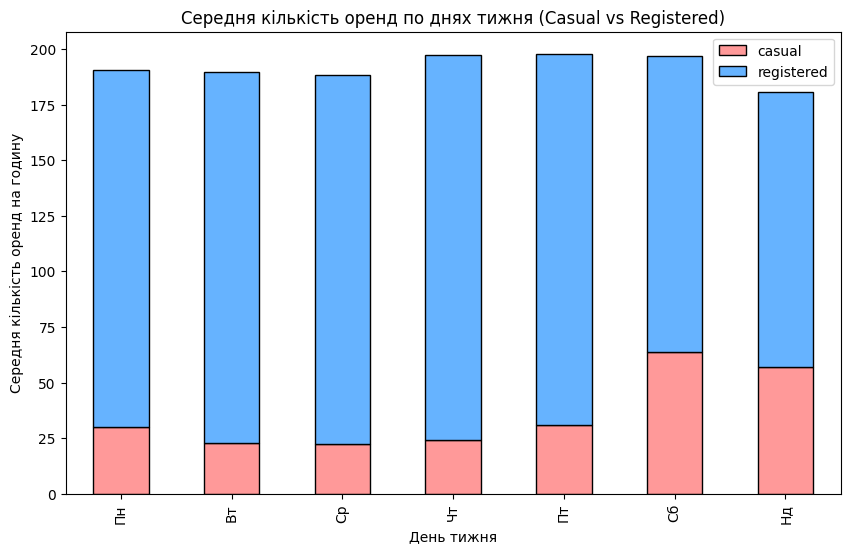

In [28]:

days_names = {0: 'Пн', 1: 'Вт', 2: 'Ср', 3: 'Чт', 4: 'Пт', 5: 'Сб', 6: 'Нд'}

weekday_avg = df.groupby(df.index.dayofweek)[['casual', 'registered']].mean()
weekday_avg.index = weekday_avg.index.map(days_names)

ax = weekday_avg.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    color=['#ff9999', '#66b3ff'],
    edgecolor='black',
    title='Середня кількість оренд по днях тижня (Casual vs Registered)'
)

ax.set_xlabel('День тижня')
ax.set_ylabel('Середня кількість оренд на годину')

Питання для інтерпретації:

1. В які дні тижня більше оренд від зареєстрованих користувачів? - в будні. відчуття що вони рєструються, щоб їздити на роботу
2. Як ви можете пояснити таку різницю в поведінці користувачів протягом тижня? - а незареєстровані користувачі більше їздять у вихідні. це мабуть просто разова оренда для прогулянок.  При цьому середнє значення приблизно однакове кожного дня. Але зменшення кількості зарестрованих користувачів невілюється збільшенням кількості людей, що не зареєструвались